In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import time
from sklearn.model_selection import train_test_split

In [2]:
import warnings
warnings.filterwarnings('ignore')


In [3]:
data_train=pd.read_csv('titanic_train.csv')
data_train.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
data_train.shape

(891, 12)

In [5]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
data_train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
data_train.Ticket.unique()

array(['A/5 21171', 'PC 17599', 'STON/O2. 3101282', '113803', '373450',
       '330877', '17463', '349909', '347742', '237736', 'PP 9549',
       '113783', 'A/5. 2151', '347082', '350406', '248706', '382652',
       '244373', '345763', '2649', '239865', '248698', '330923', '113788',
       '347077', '2631', '19950', '330959', '349216', 'PC 17601',
       'PC 17569', '335677', 'C.A. 24579', 'PC 17604', '113789', '2677',
       'A./5. 2152', '345764', '2651', '7546', '11668', '349253',
       'SC/Paris 2123', '330958', 'S.C./A.4. 23567', '370371', '14311',
       '2662', '349237', '3101295', 'A/4. 39886', 'PC 17572', '2926',
       '113509', '19947', 'C.A. 31026', '2697', 'C.A. 34651', 'CA 2144',
       '2669', '113572', '36973', '347088', 'PC 17605', '2661',
       'C.A. 29395', 'S.P. 3464', '3101281', '315151', 'C.A. 33111',
       'S.O.C. 14879', '2680', '1601', '348123', '349208', '374746',
       '248738', '364516', '345767', '345779', '330932', '113059',
       'SO/C 14885', '31012

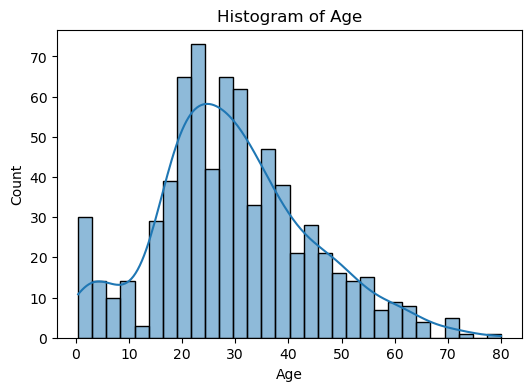

In [8]:
num_cols = ["Age"]

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data_train[col], bins=30, kde=True)
    plt.title(f"Histogram of {col}")
    plt.show()

In [9]:
data_filled=data_train.copy()
#data_filled['Age'] = pd.to_numeric(data_filled['Age'], errors='coerce')  # convert to numeric if needed
#data_filled['Age'].fillna(data_train['Age'].mode()[0],inplace=True)
#dropping null values in embarked
data_dropped=data_filled.drop([61, 829])
data_dropped.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

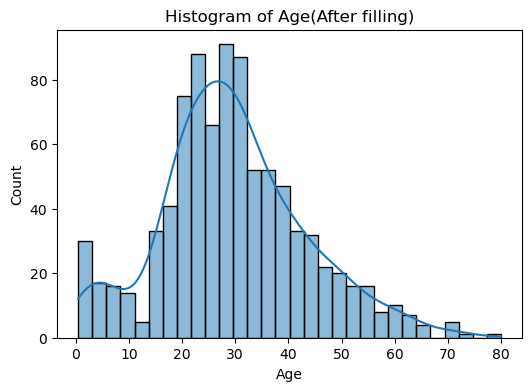

In [25]:
num_cols = ["Age"]

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df_knn[col], bins=30, kde=True)
    plt.title(f"Histogram of {col}(After filling)")
    plt.show()

In [10]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
train_encoded=data_dropped.copy()
print(train_encoded.Embarked.unique())
cols=['Sex','Embarked']
for col in cols:
    train_encoded[col]=le.fit_transform(train_encoded[col])
train_encoded.head()

['S' 'C' 'Q']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,2
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,NaN,2


In [11]:
train_encoded.Ticket.value_counts()
train_encoded.Ticket.unique()

array(['A/5 21171', 'PC 17599', 'STON/O2. 3101282', '113803', '373450',
       '330877', '17463', '349909', '347742', '237736', 'PP 9549',
       '113783', 'A/5. 2151', '347082', '350406', '248706', '382652',
       '244373', '345763', '2649', '239865', '248698', '330923', '113788',
       '347077', '2631', '19950', '330959', '349216', 'PC 17601',
       'PC 17569', '335677', 'C.A. 24579', 'PC 17604', '113789', '2677',
       'A./5. 2152', '345764', '2651', '7546', '11668', '349253',
       'SC/Paris 2123', '330958', 'S.C./A.4. 23567', '370371', '14311',
       '2662', '349237', '3101295', 'A/4. 39886', 'PC 17572', '2926',
       '113509', '19947', 'C.A. 31026', '2697', 'C.A. 34651', 'CA 2144',
       '2669', '36973', '347088', 'PC 17605', '2661', 'C.A. 29395',
       'S.P. 3464', '3101281', '315151', 'C.A. 33111', 'S.O.C. 14879',
       '2680', '1601', '348123', '349208', '374746', '248738', '364516',
       '345767', '345779', '330932', '113059', 'SO/C 14885', '3101278',
       'W./C

In [12]:
train_encoded['TicketCount'] = train_encoded.groupby('Ticket')['Ticket'].transform('count')
train_encoded

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,TicketCount
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,2,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,0,1
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,2,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,2,2
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,NaN,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",1,27.0,0,0,211536,13.0000,NaN,2,1
887,888,1,1,"Graham, Miss. Margaret Edith",0,19.0,0,0,112053,30.0000,B42,2,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",0,NaN,1,2,W./C. 6607,23.4500,NaN,2,2
889,890,1,1,"Behr, Mr. Karl Howell",1,26.0,0,0,111369,30.0000,C148,0,1


In [13]:
df_mn=train_encoded.copy()
# Extract title from name
df_mn['Title'] = df_mn['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

# Replace rare or equivalent titles
df_mn['Title'] = df_mn['Title'].replace({
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs',
    'Lady': 'Royalty',
    'Countess': 'Royalty',
    'Capt': 'Officer',
    'Col': 'Officer',
    'Major': 'Officer',
    'Dr': 'Officer',
    'Rev': 'Officer',
    'Sir': 'Royalty',
    'Don': 'Royalty',
    'Jonkheer': 'Royalty'
})

# Optional: print unique titles
print(df_mn['Title'].unique())

['Mr' 'Mrs' 'Miss' 'Master' 'Royalty' 'Officer']


In [14]:
# Group rare and equivalent titles together
df_mn['Title'] = df_mn['Title'].replace({
    'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs',
    'Countess': 'Rare', 'Lady': 'Rare', 'Sir': 'Rare',
    'Jonkheer': 'Rare', 'Don': 'Rare', 'Dona': 'Rare',
    'Dr': 'Rare', 'Rev': 'Rare', 'Col': 'Rare', 'Major': 'Rare', 'Capt': 'Rare','Royalty':'Rare','Officer':'Rare'
})


In [15]:
print(df_mn['Title'].unique())

['Mr' 'Mrs' 'Miss' 'Master' 'Rare']


In [20]:
df_mn['FamilySize'] = df_mn['SibSp'] + df_mn['Parch'] + 1
#df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
#df['FarePerPerson'] = df['Fare'] / df['FamilySize']
le=LabelEncoder()
df_mn['Title']=le.fit_transform(df_mn['Title'])
df_mn

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,TicketCount,Title,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,2,1,2,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,0,1,3,2
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,2,1,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,2,2,3,2
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,NaN,2,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",1,27.0,0,0,211536,13.0000,NaN,2,1,4,1
887,888,1,1,"Graham, Miss. Margaret Edith",0,19.0,0,0,112053,30.0000,B42,2,1,1,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",0,NaN,1,2,W./C. 6607,23.4500,NaN,2,2,1,4
889,890,1,1,"Behr, Mr. Karl Howell",1,26.0,0,0,111369,30.0000,C148,0,1,2,1


In [21]:
df_mn.Title.unique()

array([2, 3, 1, 0, 4])

In [22]:
from sklearn.ensemble import RandomForestRegressor

# Split into known and missing
age_known = df_mn[df_mn['Age'].notnull()]
age_missing = df_mn[df_mn['Age'].isnull()]

# Use useful predictors
features = ['Pclass', 'Sex', 'Fare', 'FamilySize', 'Title']

rf_reg = RandomForestRegressor(n_estimators=200, random_state=42)
rf_reg.fit(age_known[features], age_known['Age'])

predicted_ages = rf_reg.predict(age_missing[features])
df_mn.loc[df_mn['Age'].isnull(), 'Age'] = predicted_ages


In [24]:
df_knn=df_mn.copy()
df_knn.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
TicketCount      0
Title            0
FamilySize       0
dtype: int64

In [12]:
#using imputer for filling age null values
cols=['Age','Survived','Pclass','Sex','Fare','Embarked']
knn=KNNImputer(n_neighbors=5)
df_knn=train_encoded.copy()
df_knn[cols]=knn.fit_transform(df_knn[cols])

In [26]:
df_knn.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
TicketCount      0
Title            0
FamilySize       0
dtype: int64

In [27]:
df_knn.Embarked.unique()

array([2, 0, 1])

In [28]:
df_k=df_knn.copy()
df_k['Cabin'].fillna('no_cabin',inplace=True)
df_k.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
TicketCount    0
Title          0
FamilySize     0
dtype: int64

In [29]:
print(df_k.Cabin.value_counts())
df_k.Cabin.unique()

Cabin
no_cabin       687
G6               4
C23 C25 C27      4
B96 B98          4
F2               3
              ... 
E34              1
C7               1
C54              1
E36              1
C148             1
Name: count, Length: 147, dtype: int64


array(['no_cabin', 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'C83', 'F33', 'F G73',
       'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101', 'F E69',
       'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4', 'A32',
       'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35', 'C87',
       'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19', 'B49',
       'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54', 'B57 B59 B63 B66',
       'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40', 'T', 'C128',
       'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44', 'A34', 'C104',
       'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14', 'B37', 'C30',
       'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38', 'B39', 'B22',
       'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68', 'B41', 'A20',
       'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48', 'E58', 'C126',
       'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63', 'C62 C64',
      

In [30]:
#adding feature for cabin
df_k['Cabin_count']=df_k.groupby('Cabin')['Cabin'].transform('count')
df_k

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,TicketCount,Title,FamilySize,Cabin_count
0,1,0,3,"Braund, Mr. Owen Harris",1,22.00000,1,0,A/5 21171,7.2500,no_cabin,2,1,2,2,687
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.00000,1,0,PC 17599,71.2833,C85,0,1,3,2,1
2,3,1,3,"Heikkinen, Miss. Laina",0,26.00000,0,0,STON/O2. 3101282,7.9250,no_cabin,2,1,1,1,687
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.00000,1,0,113803,53.1000,C123,2,2,3,2,2
4,5,0,3,"Allen, Mr. William Henry",1,35.00000,0,0,373450,8.0500,no_cabin,2,1,2,1,687
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",1,27.00000,0,0,211536,13.0000,no_cabin,2,1,4,1,687
887,888,1,1,"Graham, Miss. Margaret Edith",0,19.00000,0,0,112053,30.0000,B42,2,1,1,1,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",0,4.81629,1,2,W./C. 6607,23.4500,no_cabin,2,2,1,4,687
889,890,1,1,"Behr, Mr. Karl Howell",1,26.00000,0,0,111369,30.0000,C148,0,1,2,1,1


In [21]:
df_mn=df_k.copy()
# Extract title from name
df_mn['Title'] = df_mn['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

# Replace rare or equivalent titles
df_mn['Title'] = df_mn['Title'].replace({
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs',
    'Lady': 'Royalty',
    'Countess': 'Royalty',
    'Capt': 'Officer',
    'Col': 'Officer',
    'Major': 'Officer',
    'Dr': 'Officer',
    'Rev': 'Officer',
    'Sir': 'Royalty',
    'Don': 'Royalty',
    'Jonkheer': 'Royalty'
})

# Optional: print unique titles
print(df_mn['Title'].unique())


['Mr' 'Mrs' 'Miss' 'Master' 'Royalty' 'Officer']


In [22]:
# Group rare and equivalent titles together
df_mn['Title'] = df_mn['Title'].replace({
    'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs',
    'Countess': 'Rare', 'Lady': 'Rare', 'Sir': 'Rare',
    'Jonkheer': 'Rare', 'Don': 'Rare', 'Dona': 'Rare',
    'Dr': 'Rare', 'Rev': 'Rare', 'Col': 'Rare', 'Major': 'Rare', 'Capt': 'Rare','Royalty':'Rare','Officer':'Rare'
})


In [23]:
print(df_mn['Title'].unique())

['Mr' 'Mrs' 'Miss' 'Master' 'Rare']


In [32]:
#Dropping unimportant features
data_dropped=df_k.drop(columns=['Name', 'Ticket','Cabin','PassengerId','SibSp','Parch','Embarked','Cabin_count','Title','TicketCount','FamilySize'])
data_dropped.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,1,22.0,7.2500
1,1,1,0,38.0,71.2833
2,1,3,0,26.0,7.9250
3,1,1,0,35.0,53.1000
4,0,3,1,35.0,8.0500


In [95]:
data_dropped.TicketCount.unique()

array([1, 2, 4, 3, 7, 5, 6], dtype=int64)

In [26]:
#label ecoding for cabin count only
#from sklearn.preprocessing import 
le=LabelEncoder()
#data_dropped['Cabin_count']=le.fit_transform(data_dropped['Cabin_count'])
#data_dropped['Title']=le.fit_transform(data_dropped['Title'])

data_dropped
data_dropped.Title.unique()

AttributeError: 'DataFrame' object has no attribute 'Title'

In [36]:
data_dropped['Survived']=data_dropped['Survived'].astype(int)
data_dropped['Pclass']=data_dropped['Pclass'].astype(int)
data_dropped['Sex']=data_dropped['Sex'].astype(int)
data_dropped['Age']=data_dropped['Age'].astype(float)
data_dropped['Fare']=data_dropped['Fare'].astype(float)

#data_dropped['SibSp']=data_dropped['SibSp'].astype(int)
#data_dropped['Parch']=data_dropped['Parch'].astype(int)
#data_dropped['Embarked']=data_dropped['Embarked'].astype(int)


In [37]:
data_dropped.Survived.unique()

array([0, 1])

In [38]:
data_dropped

,Survived,Pclass,Sex,Age,Fare
0,0,3,1,22.00000,7.2500
1,1,1,0,38.00000,71.2833
2,1,3,0,26.00000,7.9250
3,1,1,0,35.00000,53.1000
4,0,3,1,35.00000,8.0500
...,...,...,...,...,...
886,0,2,1,27.00000,13.0000
887,1,1,0,19.00000,30.0000
888,0,3,0,4.81629,23.4500
889,1,1,1,26.00000,30.0000


In [39]:
#StandardScaling
data_n=data_dropped.copy()
nml=StandardScaler()
num_cols=['Age','Fare']
data_n[num_cols]=nml.fit_transform(data_n[num_cols])
data_n

,Survived,Pclass,Sex,Age,Fare
0,0,3,1,-0.555021,-0.500240
1,1,1,0,0.610357,0.788947
2,1,3,0,-0.263676,-0.486650
3,1,1,0,0.391849,0.422861
4,0,3,1,0.391849,-0.484133
...,...,...,...,...,...
886,0,2,1,-0.190840,-0.384475
887,1,1,0,-0.773529,-0.042213
888,0,3,0,-1.806615,-0.174084
889,1,1,1,-0.263676,-0.042213


# KNN Start

=== K-Nearest Neighbors (KNN) with 10-Fold Cross Validation ===
Computation Time      : 0.16 seconds
Mean Accuracy         : 0.8313
Standard Deviation    : 0.0400
Accuracy         : [0.85393258 0.83146067 0.80898876 0.82022472 0.75280899 0.80898876
 0.82022472 0.91011236 0.83146067 0.875     ]

Classification Report:
              precision    recall  f1-score   support

          no       0.83      0.92      0.87       549
         yes       0.84      0.69      0.76       340

    accuracy                           0.83       889
   macro avg       0.83      0.81      0.81       889
weighted avg       0.83      0.83      0.83       889



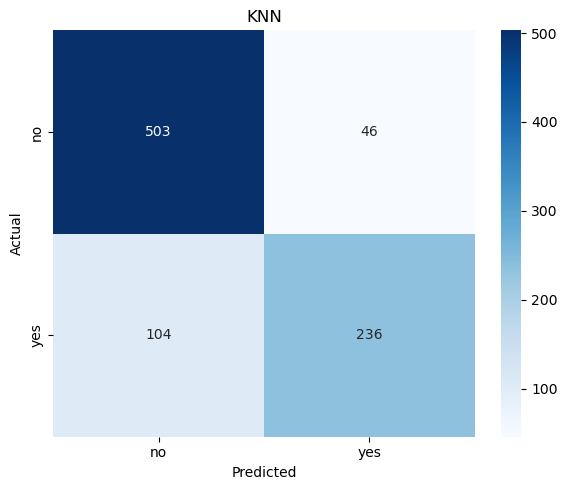

In [47]:
X=data_n.drop(columns=['Survived'])
y=data_n['Survived']
from sklearn.neighbors import KNeighborsClassifier

class_=['no','yes']
# Step 4: Initialize Logestic Regression model and StratifiedKFold
knn_model = KNeighborsClassifier(metric= 'euclidean', n_neighbors= 4, p= 1)  # You can tune k later
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Step 5: Start timing
start_time = time.time()

# Step 6: Cross-validation
cv_scores = cross_val_score(knn_model, X, y, cv=kfold, scoring='accuracy')
mean_acc = cv_scores.mean()
std_acc = cv_scores.std()

# Step 7: Predictions for evaluation
y_pred_cv = cross_val_predict(knn_model, X, y, cv=kfold)

# Step 8: End timing
runtime = time.time() - start_time

# === Results ===
print("=== K-Nearest Neighbors (KNN) with 10-Fold Cross Validation ===")
print(f"Computation Time      : {runtime:.2f} seconds")
print(f"Mean Accuracy         : {mean_acc:.4f}")
print(f"Standard Deviation    : {std_acc:.4f}")
print(f"Accuracy         : {cv_scores}")

print("\nClassification Report:")
print(classification_report(y, y_pred_cv, target_names=class_))

# Step 9: Confusion Matrix
conf_mat = confusion_matrix(y, y_pred_cv)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_, yticklabels=class_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN")
plt.tight_layout()
plt.show()

In [48]:
# Accuracy on train and test
from sklearn.metrics import roc_curve, auc
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
knn_model.fit(X_train, y_train)
train_acc = knn_model.score(X_train, y_train)
test_acc = knn_model.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Training Accuracy: 0.870604781997187
Testing Accuracy : 0.8258426966292135


In [112]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
import numpy as np

# Split data
X = data_n.drop(columns=['Survived'])
y = data_n['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardization (important for KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# KNN model
knn = KNeighborsClassifier()

# Try different k values
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
    'p': [1, 2]
}

grid = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)

# Evaluate on test set
best_knn = grid.best_estimator_
test_acc = best_knn.score(X_test_scaled, y_test)
print("Test accuracy:", test_acc)


Best parameters: {'metric': 'manhattan', 'n_neighbors': 7, 'p': 1, 'weights': 'uniform'}
Best CV accuracy: 0.832620900226534
Test accuracy: 0.8314606741573034


# Linear Regression Start

In [113]:

X=data_n.drop(columns=['Survived'])
y=data_n['Survived']
# numeric columns used
num_cols = ['Age','Fare']
from sklearn.metrics import roc_curve, auc
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# preprocessor: scale numeric columns only; leave other columns (one-hot) as-is
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols)
], remainder='passthrough')   # keeps one-hot columns

# Pipeline
pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(solver='lbfgs', max_iter=2000))
])

# Grid to search: tune regularization C and class_weight
param_grid = {
    'clf__C': [0.01, 0.1, 1, 10, 100],
    'clf__class_weight': [None, 'balanced', {0:1, 1:3}, {0:1, 1:5}]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1', n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)   # use X, y_encoded from your workspace

print("Best params:", grid.best_params_)
print("Best CV f1:", grid.best_score_)

# Evaluate best estimator via cross-validated predictions
best = grid.best_estimator_
y_pred = cross_val_predict(best, X, y, cv=cv, n_jobs=-1)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'clf__C': 10, 'clf__class_weight': None}
Best CV f1: 0.7400252741429212


In [115]:
# Accuracy on train and test
from sklearn.metrics import roc_curve, auc
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#LR_model.fit(X_train, y_train)
train_acc = grid.score(X_train, y_train)
test_acc = grid.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Training Accuracy: 0.7429643527204502
Testing Accuracy : 0.7638888888888888


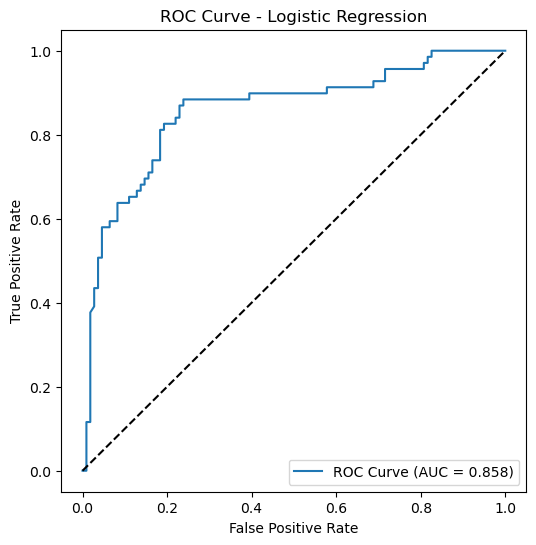

In [39]:

from sklearn.metrics import roc_curve, auc
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

y_pred_proba = best.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.show()




              precision    recall  f1-score   support

    Rejected       0.83      0.85      0.84       549
    Approved       0.75      0.71      0.73       340

    accuracy                           0.80       889
   macro avg       0.79      0.78      0.79       889
weighted avg       0.80      0.80      0.80       889

ROC AUC (cv): 0.8528567924250601


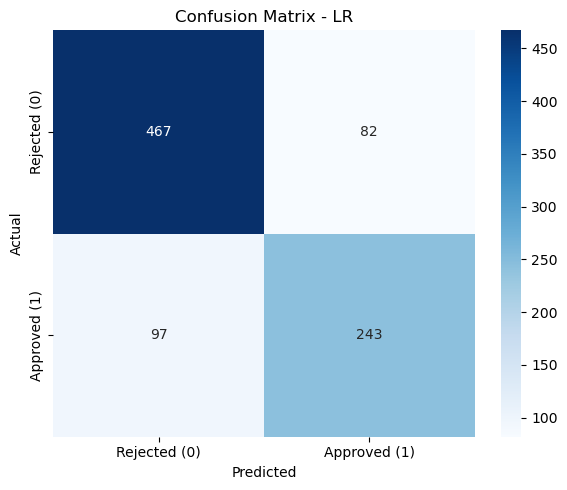

In [40]:
print(classification_report(y, y_pred, target_names=['Rejected','Approved']))
print("ROC AUC (cv):", np.mean(cross_val_score(best, X, y, cv=cv, scoring='roc_auc')))

# Confusion Matrix
class_names = ["Rejected (0)", "Approved (1)"]

conf_mat = confusion_matrix(y, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_mat, annot=True, fmt='g', cmap='Blues',xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - LR")
plt.tight_layout()
plt.show()

In [139]:
data_dropped.Survived.value_counts()

Survived
0    549
1    340
Name: count, dtype: int64

In [75]:
data_n

,Survived,Pclass,Sex,Age,Fare
0,0,3,1,-0.578925,-0.500240
1,1,1,0,0.595867,0.788947
2,1,3,0,-0.285227,-0.486650
3,1,1,0,0.375594,0.422861
4,0,3,1,0.375594,-0.484133
...,...,...,...,...,...
886,0,2,1,-0.211803,-0.384475
887,1,1,0,-0.799199,-0.042213
888,0,3,0,-0.153063,-0.174084
889,1,1,1,-0.285227,-0.042213


=== K-Nearest Neighbors (KNN) with 10-Fold Cross Validation ===
Computation Time      : 0.14 seconds
Mean Accuracy         : 0.7986
Standard Deviation    : 0.0378
Accuracy         : [0.83146067 0.7752809  0.78651685 0.86516854 0.71910112 0.80898876
 0.79775281 0.83146067 0.7752809  0.79545455]

Classification Report:
              precision    recall  f1-score   support

          no       0.83      0.85      0.84       549
         yes       0.75      0.71      0.73       340

    accuracy                           0.80       889
   macro avg       0.79      0.78      0.79       889
weighted avg       0.80      0.80      0.80       889



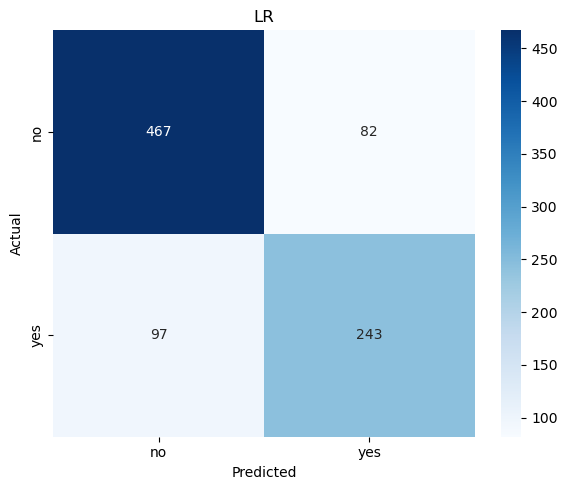

In [41]:

#X = data_final.drop(columns=['Species'])  # Features
#y = data_final['Species']
X=data_n.drop(columns=['Survived'])
y=data_n['Survived']

class_=['no','yes']
# Step 4: Initialize Logestic Regression model and StratifiedKFold
LR_model = LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=2000)  # You can tune k later
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Step 5: Start timing
start_time = time.time()

# Step 6: Cross-validation
cv_scores = cross_val_score(LR_model, X, y, cv=kfold, scoring='accuracy')
mean_acc = cv_scores.mean()
std_acc = cv_scores.std()

# Step 7: Predictions for evaluation
y_pred_cv = cross_val_predict(LR_model, X, y, cv=kfold)

# Step 8: End timing
runtime = time.time() - start_time

# === Results ===
print("=== K-Nearest Neighbors (KNN) with 10-Fold Cross Validation ===")
print(f"Computation Time      : {runtime:.2f} seconds")
print(f"Mean Accuracy         : {mean_acc:.4f}")
print(f"Standard Deviation    : {std_acc:.4f}")
print(f"Accuracy         : {cv_scores}")

print("\nClassification Report:")
print(classification_report(y, y_pred_cv, target_names=class_))

# Step 9: Confusion Matrix
conf_mat = confusion_matrix(y, y_pred_cv)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_, yticklabels=class_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LR")
plt.tight_layout()
plt.show()

In [42]:
# Accuracy on train and test
from sklearn.metrics import roc_curve, auc
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
LR_model.fit(X_train, y_train)
train_acc = LR_model.score(X_train, y_train)
test_acc = LR_model.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Training Accuracy: 0.8073136427566807
Testing Accuracy : 0.8089887640449438


In [323]:
#saving model
import joblib

# after training your model (example)
# model = LogisticRegression(...)
# model.fit(X_train, y_train)

joblib.dump(LR_model, 'titanic_model_LR.pkl')
print("Model saved successfully!")



Model saved successfully!


# Random Forest(Start)

Random Forest Accuracy: 0.8357836602551896
=== Random Forest (RF) with 10-Fold Cross Validation ===
Computation Time      : 14.69 seconds
Mean Accuracy         : 0.8302
Standard Deviation    : 0.0246
Accuracy         : [0.84269663 0.83146067 0.80898876 0.82022472 0.80898876 0.85393258
 0.82022472 0.86516854 0.78651685 0.86363636]

Classification Report:
              precision    recall  f1-score   support

          no       0.84      0.90      0.87       549
         yes       0.82      0.71      0.76       340

    accuracy                           0.83       889
   macro avg       0.83      0.81      0.82       889
weighted avg       0.83      0.83      0.83       889



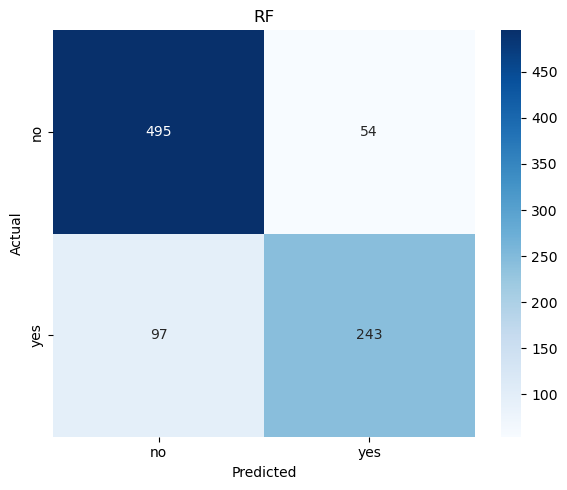

In [43]:
#trying Random Forest
X=data_n.drop(columns=['Survived'])
y=data_n['Survived']
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = RandomForestClassifier(n_estimators=500, random_state=42, max_depth=10, min_samples_split=5)
scores = cross_val_score(rf, X, y, cv=5, scoring='accuracy')
print("Random Forest Accuracy:", scores.mean())

# Step 5: Start timing
start_time = time.time()

# Step 6: Cross-validation
cv_scores = cross_val_score(rf, X, y, cv=kfold, scoring='accuracy')
mean_acc = cv_scores.mean()
std_acc = cv_scores.std()

# Step 7: Predictions for evaluation
y_pred_cv = cross_val_predict(rf, X, y, cv=kfold)

# Step 8: End timing
runtime = time.time() - start_time

class_=['no','yes']
# === Results ===
print("=== Random Forest (RF) with 10-Fold Cross Validation ===")
print(f"Computation Time      : {runtime:.2f} seconds")
print(f"Mean Accuracy         : {mean_acc:.4f}")
print(f"Standard Deviation    : {std_acc:.4f}")
print(f"Accuracy         : {cv_scores}")

print("\nClassification Report:")
print(classification_report(y, y_pred_cv, target_names=class_))

# Step 9: Confusion Matrix
conf_mat = confusion_matrix(y, y_pred_cv)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_, yticklabels=class_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RF")
plt.tight_layout()
plt.show()


In [50]:
# Accuracy on train and test
from sklearn.metrics import roc_curve, auc
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf.fit(X_train, y_train)
train_acc = rf.score(X_train, y_train)
test_acc = rf.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Training Accuracy: 0.9324894514767933
Testing Accuracy : 0.8202247191011236


Random Forest Accuracy: 0.8357836602551896
=== Random Forest (RF) with 10-Fold Cross Validation ===
Computation Time      : 72.69 seconds
Mean Accuracy         : 0.8212
Standard Deviation    : 0.0241
Accuracy         : [0.82022472 0.80898876 0.79775281 0.82022472 0.79775281 0.84269663
 0.82022472 0.85393258 0.78651685 0.86363636]

Classification Report:
              precision    recall  f1-score   support

          no       0.84      0.90      0.87       549
         yes       0.82      0.71      0.76       340

    accuracy                           0.83       889
   macro avg       0.83      0.81      0.82       889
weighted avg       0.83      0.83      0.83       889



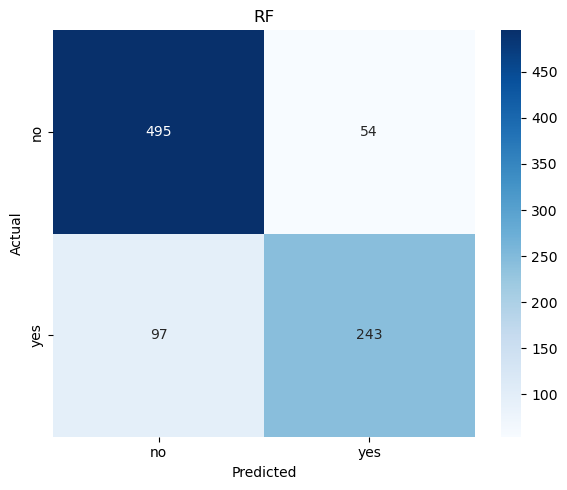

In [44]:
#experimenting

#trying Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf1 = RandomForestClassifier(n_estimators=1000, random_state=42, max_depth=15, min_samples_split=6)
scores = cross_val_score(rf, X, y, cv=5, scoring='accuracy')
print("Random Forest Accuracy:", scores.mean())

# Step 6: Cross-validation
cv_scores = cross_val_score(rf1, X, y, cv=kfold, scoring='accuracy')
mean_acc = cv_scores.mean()
std_acc = cv_scores.std()

# Step 7: Predictions for evaluation
y_pred_cv = cross_val_predict(rf, X, y, cv=kfold)

# Step 8: End timing
runtime = time.time() - start_time

class_=['no','yes']
# === Results ===
print("=== Random Forest (RF) with 10-Fold Cross Validation ===")
print(f"Computation Time      : {runtime:.2f} seconds")
print(f"Mean Accuracy         : {mean_acc:.4f}")
print(f"Standard Deviation    : {std_acc:.4f}")
print(f"Accuracy         : {cv_scores}")

print("\nClassification Report:")
print(classification_report(y, y_pred_cv, target_names=class_))

# Step 9: Confusion Matrix
conf_mat = confusion_matrix(y, y_pred_cv)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_, yticklabels=class_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RF")
plt.tight_layout()
plt.show()

In [71]:
# Accuracy on train and test
from sklearn.metrics import roc_curve, auc
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf1.fit(X_train, y_train)
train_acc = rf1.score(X_train, y_train)
test_acc = rf1.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Training Accuracy: 0.9367088607594937
Testing Accuracy : 0.8202247191011236


In [53]:
#Saving random forest
import joblib
joblib.dump(rf, 'titanic_model_random.pkl')
print("Model saved successfully!")

Model saved successfully!


In [288]:

X=data_n.drop(columns=['Survived'])
y=data_n['Survived']
# numeric columns used
num_cols = ['Age','Fare']

# preprocessor: scale numeric columns only; leave other columns (one-hot) as-is
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols)
], remainder='passthrough')   # keeps one-hot columns

# Pipeline
pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', RandomForestClassifier(random_state=42))
])

# Grid to search: tune regularization C and class_weight
param_grid = {
    'clf__n_estimators': [100, 300, 500,1000,2000,2500],
    'clf__max_depth': [5, 10, 15, None],
    'clf__min_samples_split': [2, 5, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=1)
grid.fit(X, y)   # use X, y_encoded from your workspace

print("Best params:", grid.best_params_)
print("Best CV f1:", grid.best_score_)

# Evaluate best estimator via cross-validated predictions
best = grid.best_estimator_
y_pred = cross_val_predict(best, X, y, cv=cv, n_jobs=-1)


Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best params: {'clf__max_depth': 10, 'clf__min_samples_split': 2, 'clf__n_estimators': 100}
Best CV f1: 0.7799530851137225


In [279]:
train_acc = grid.score(X_train, y_train)
test_acc = grid.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Training Accuracy: 0.7282229965156795
Testing Accuracy : 0.7712418300653595


# XGboost start

XGBoost Accuracy: 0.8414070480081716
=== XGboost (xgb) with 10-Fold Cross Validation ===
Computation Time      : 792.83 seconds
Mean Accuracy         : 0.8414
Standard Deviation    : 0.0215
Accuracy         : [0.87640449 0.84269663 0.83146067 0.84269663 0.84269663 0.82022472
 0.82022472 0.87640449 0.80898876 0.85227273]

Classification Report:
              precision    recall  f1-score   support

          no       0.85      0.91      0.88       549
         yes       0.83      0.73      0.78       340

    accuracy                           0.84       889
   macro avg       0.84      0.82      0.83       889
weighted avg       0.84      0.84      0.84       889



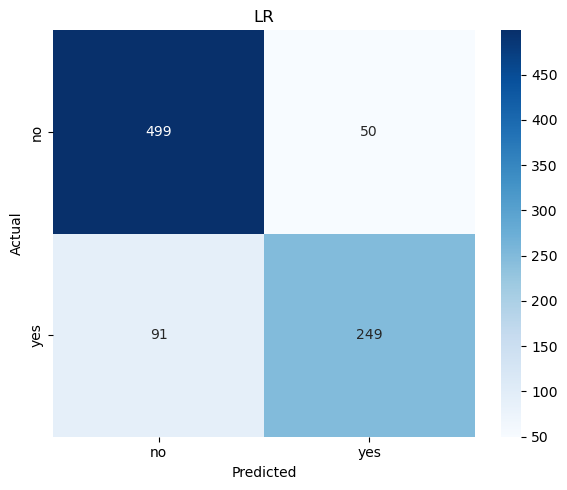

In [57]:
#trying xgboost
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=2000, learning_rate=0.04, max_depth=2, random_state=42)
scores = cross_val_score(xgb, X, y, cv=kfold, scoring='accuracy')
print("XGBoost Accuracy:", scores.mean())


# Step 6: Cross-validation
cv_scores = cross_val_score(xgb, X, y, cv=kfold, scoring='accuracy')
mean_acc = cv_scores.mean()
std_acc = cv_scores.std()

# Step 7: Predictions for evaluation
y_pred_cv = cross_val_predict(xgb, X, y, cv=kfold)

# Step 8: End timing
runtime = time.time() - start_time

class_=['no','yes']
# === Results ===
print("=== XGboost (xgb) with 10-Fold Cross Validation ===")
print(f"Computation Time      : {runtime:.2f} seconds")
print(f"Mean Accuracy         : {mean_acc:.4f}")
print(f"Standard Deviation    : {std_acc:.4f}")
print(f"Accuracy         : {cv_scores}")

print("\nClassification Report:")
print(classification_report(y, y_pred_cv, target_names=class_))

# Step 9: Confusion Matrix
conf_mat = confusion_matrix(y, y_pred_cv)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_, yticklabels=class_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LR")
plt.tight_layout()
plt.show()


In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
xgb.fit(X_train, y_train)
train_acc = xgb.score(X_train, y_train)
test_acc = xgb.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Training Accuracy: 0.9212376933895922
Testing Accuracy : 0.8258426966292135


# Model

In [348]:
joblib.dump(xgb, 'titanic_model_xgboost.pkl')
print("Model saved successfully!")

Model saved successfully!


# Combined

Voting Ensemble Accuracy: 0.8290357392242746
=== XGboost (xgb) with 10-Fold Cross Validation ===
Computation Time      : 294.69 seconds
Mean Accuracy         : 0.8200
Standard Deviation    : 0.0332
Accuracy         : [0.83146067 0.84269663 0.75280899 0.86516854 0.79775281 0.83146067
 0.79775281 0.85393258 0.78651685 0.84090909]

Classification Report:
              precision    recall  f1-score   support

          no       0.83      0.89      0.86       549
         yes       0.79      0.71      0.75       340

    accuracy                           0.82       889
   macro avg       0.81      0.80      0.81       889
weighted avg       0.82      0.82      0.82       889



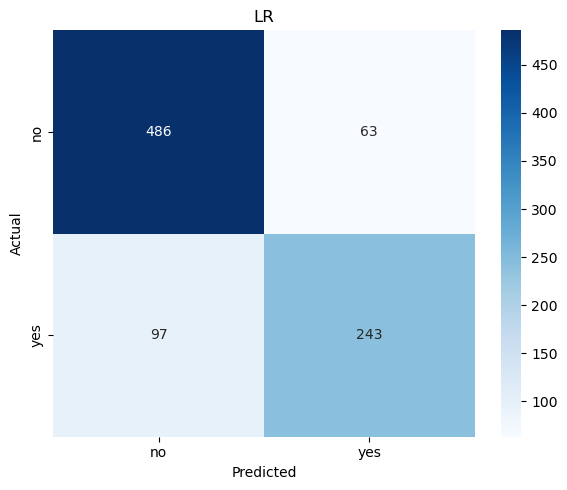

In [47]:
#combine models
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

X1=data_n.drop(columns=['Survived'])
y1=data_n['Survived']
from sklearn.ensemble import VotingClassifier

voting = VotingClassifier(estimators=[
    ('knn',KNeighborsClassifier()),
    
    ('rf', RandomForestClassifier(n_estimators=500, random_state=0, max_depth=10, min_samples_split=5)),
    ('xgb', XGBClassifier(n_estimators=2000, learning_rate=0.04, max_depth=2, random_state=42))
], voting='soft')

scores = cross_val_score(voting, X1, y1, cv=5, scoring='accuracy')
print("Voting Ensemble Accuracy:", scores.mean())


# Step 6: Cross-validation
cv_scores = cross_val_score(voting, X1, y1, cv=kfold, scoring='accuracy')
mean_acc = cv_scores.mean()
std_acc = cv_scores.std()

# Step 7: Predictions for evaluation
y_pred_cv = cross_val_predict(voting, X1, y1, cv=kfold)

# Step 8: End timing
runtime = time.time() - start_time

class_=['no','yes']
# === Results ===
print("=== XGboost (xgb) with 10-Fold Cross Validation ===")
print(f"Computation Time      : {runtime:.2f} seconds")
print(f"Mean Accuracy         : {mean_acc:.4f}")
print(f"Standard Deviation    : {std_acc:.4f}")
print(f"Accuracy         : {cv_scores}")

print("\nClassification Report:")
print(classification_report(y1, y_pred_cv, target_names=class_))

# Step 9: Confusion Matrix
conf_mat = confusion_matrix(y1, y_pred_cv)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_, yticklabels=class_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LR")
plt.tight_layout()
plt.show()

In [105]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
voting.fit(X_train, y_train)
train_acc = voting.score(X_train, y_train)
test_acc = voting.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

Training Accuracy: 0.9212376933895922
Testing Accuracy : 0.8314606741573034


In [74]:
joblib.dump(voting, 'titanic_model_combined_final.pkl')
print("Model saved successfully!")

Model saved successfully!


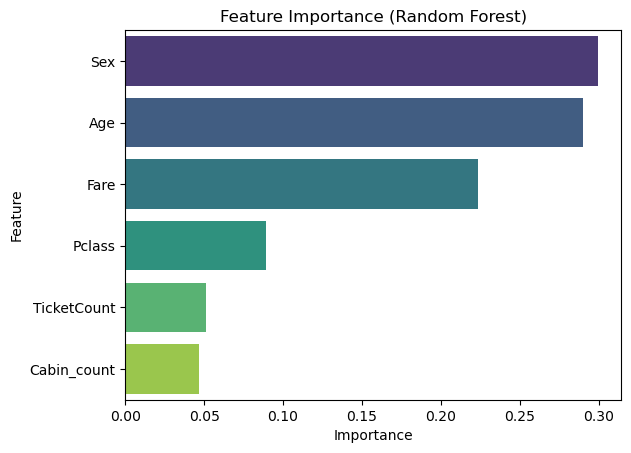

       Feature  Importance
1          Sex    0.299425
2          Age    0.290206
3         Fare    0.223406
0       Pclass    0.089512
4  TicketCount    0.050889
5  Cabin_count    0.046562


In [51]:
# Features & target
X = data_n.drop(columns=['Survived'])
y = data_n["Survived"]

# Train Random Forest
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X, y)

# Get feature importance
importance = model.feature_importances_
feature_names = X.columns

# Put into DataFrame
feat_importance = pd.DataFrame({"Feature": feature_names, "Importance": importance})
feat_importance = feat_importance.sort_values(by="Importance", ascending=False)

# Plot
sns.barplot(x="Importance", y="Feature", data=feat_importance, palette="viridis")
plt.title("Feature Importance (Random Forest)")
plt.show()

print(feat_importance)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [40]:
data_train.Embarked.isnull().sum()

2

In [53]:
data_train[data_train['Embarked'].isnull()].index

Index([61, 829], dtype='int64')

In [58]:
#dropping null values in embarked
data_train=data_train.drop([61, 829])

In [59]:
data_train.Embarked.isnull().sum()

0

In [60]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
train_encoded=data_train.copy()
cols=['Sex','Embarked']
for col in cols:
    train_encoded[col]=le.fit_transform(train_encoded[col])
train_encoded.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,2
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,NaN,2


In [61]:
train_encoded.Embarked.unique()

array([2, 0, 1])

In [41]:
data_test=pd.read_csv('titanic_test.csv')
data_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [63]:
data_test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

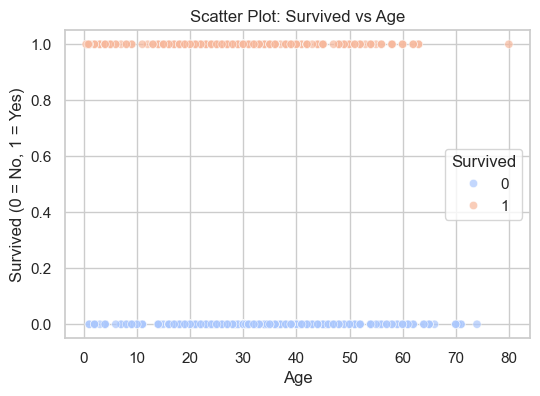

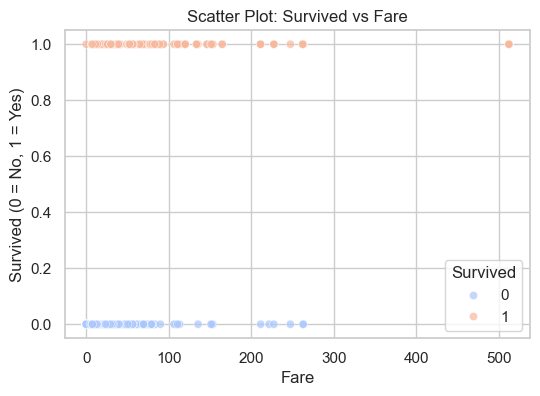

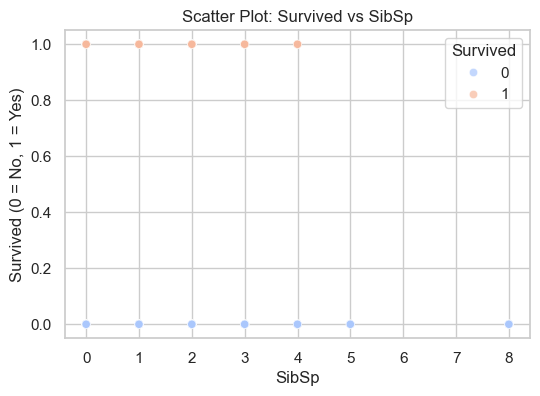

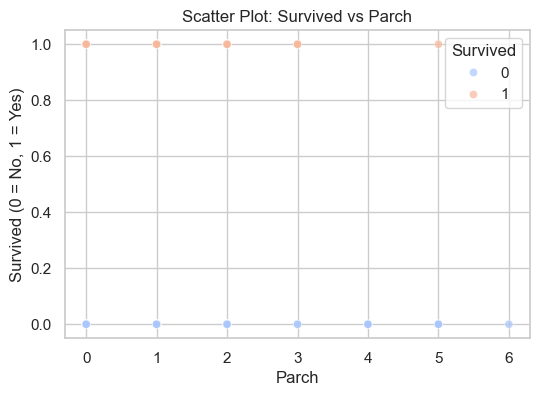

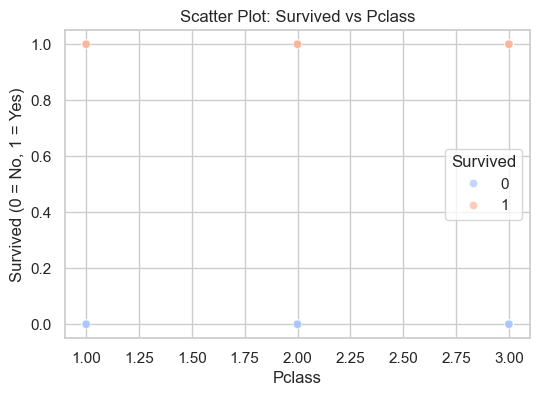

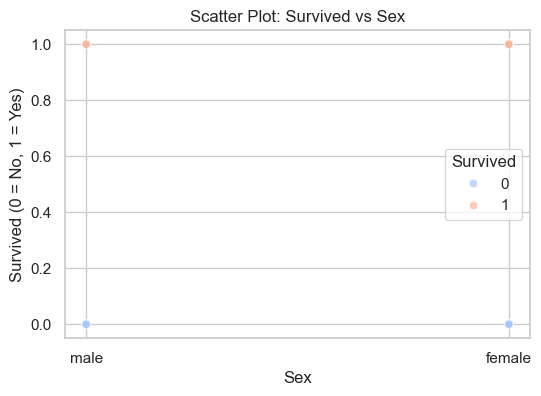

In [27]:
# Set Seaborn style
sns.set(style="whitegrid", palette="muted")

# -------- Scatter plots for numeric features --------
numeric_features = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass','Sex']
for col in numeric_features:
    plt.figure(figsize=(6,4))
    sns.scatterplot(x=col, y='Survived', data=data_train, hue='Survived', alpha=0.7, palette='coolwarm')
    plt.title(f"Scatter Plot: Survived vs {col}")
    plt.xlabel(col)
    plt.ylabel("Survived (0 = No, 1 = Yes)")
    plt.show()

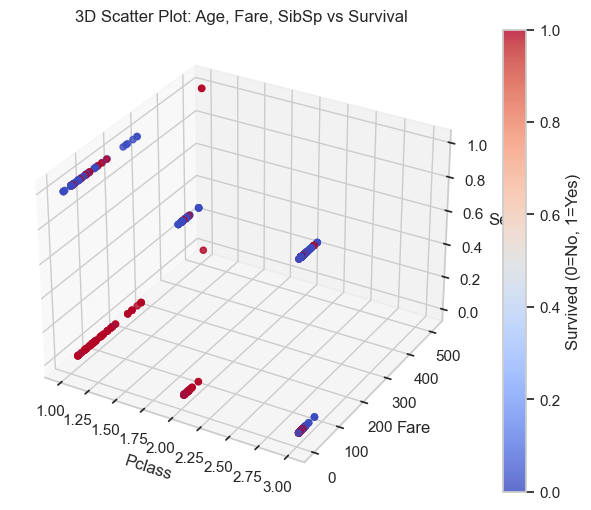

In [21]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

# Example: Age, Fare, and SibSp
sc = ax.scatter(
    train_encoded['Pclass'], train_encoded['Fare'], train_encoded['Sex'],
    c=train_encoded['Survived'], cmap='coolwarm', alpha=0.8
)

ax.set_xlabel('Pclass')
ax.set_ylabel('Fare')
ax.set_zlabel('Sex')
plt.title('3D Scatter Plot: Age, Fare, SibSp vs Survival')
plt.colorbar(sc, label='Survived (0=No, 1=Yes)')
plt.show()

In [22]:
train_encoded.Pclass.isnull().sum()

0

In [23]:
train_encoded.Sex.unique()

array([1, 0])

In [26]:
train_encoded.Sex.value_counts(normalize=True)

Sex
1    0.647587
0    0.352413
Name: proportion, dtype: float64

In [28]:
train_encoded.Survived.value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64